# OpsPilot: normal versus faulty telemetry

Load the latest virtual simulation output, inspect service behavior, and compare each known fault interval with its preceding baseline. Run `opspilot simulate --hours 24 --seed 1` from the repository root first.

In [4]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
repo_root = Path.cwd()
if not (repo_root / "data").exists():
    repo_root = repo_root.parent
data_root = repo_root / "data"
metric_files = sorted((data_root / "processed").glob("simulation_*_metrics.parquet"), key=lambda p: p.stat().st_mtime)
if not metric_files:
    raise FileNotFoundError("No metrics found. Run the simulator from the repository root first.")
metrics_path = metric_files[-1]
run_id = metrics_path.name.removeprefix("simulation_").removesuffix("_metrics.parquet")
truth_path = data_root / "ground_truth" / f"simulation_{run_id}_faults.jsonl"
metrics = pd.read_parquet(metrics_path)
metrics["ts"] = pd.to_datetime(metrics["ts"], utc=True)
faults = pd.read_json(truth_path, lines=True) if truth_path.exists() else pd.DataFrame()
metrics_path, metrics.shape, faults.shape

(WindowsPath('c:/Users/pulki/OneDrive/Desktop/OpsPilot/data/processed/simulation_run-0650babc257c_metrics.parquet'),
 (51840, 16),
 (5, 10))

## Service telemetry over time

Fault windows are shaded using simulator ground truth. The chart is descriptive; detectors and thresholds are evaluated in later phases.

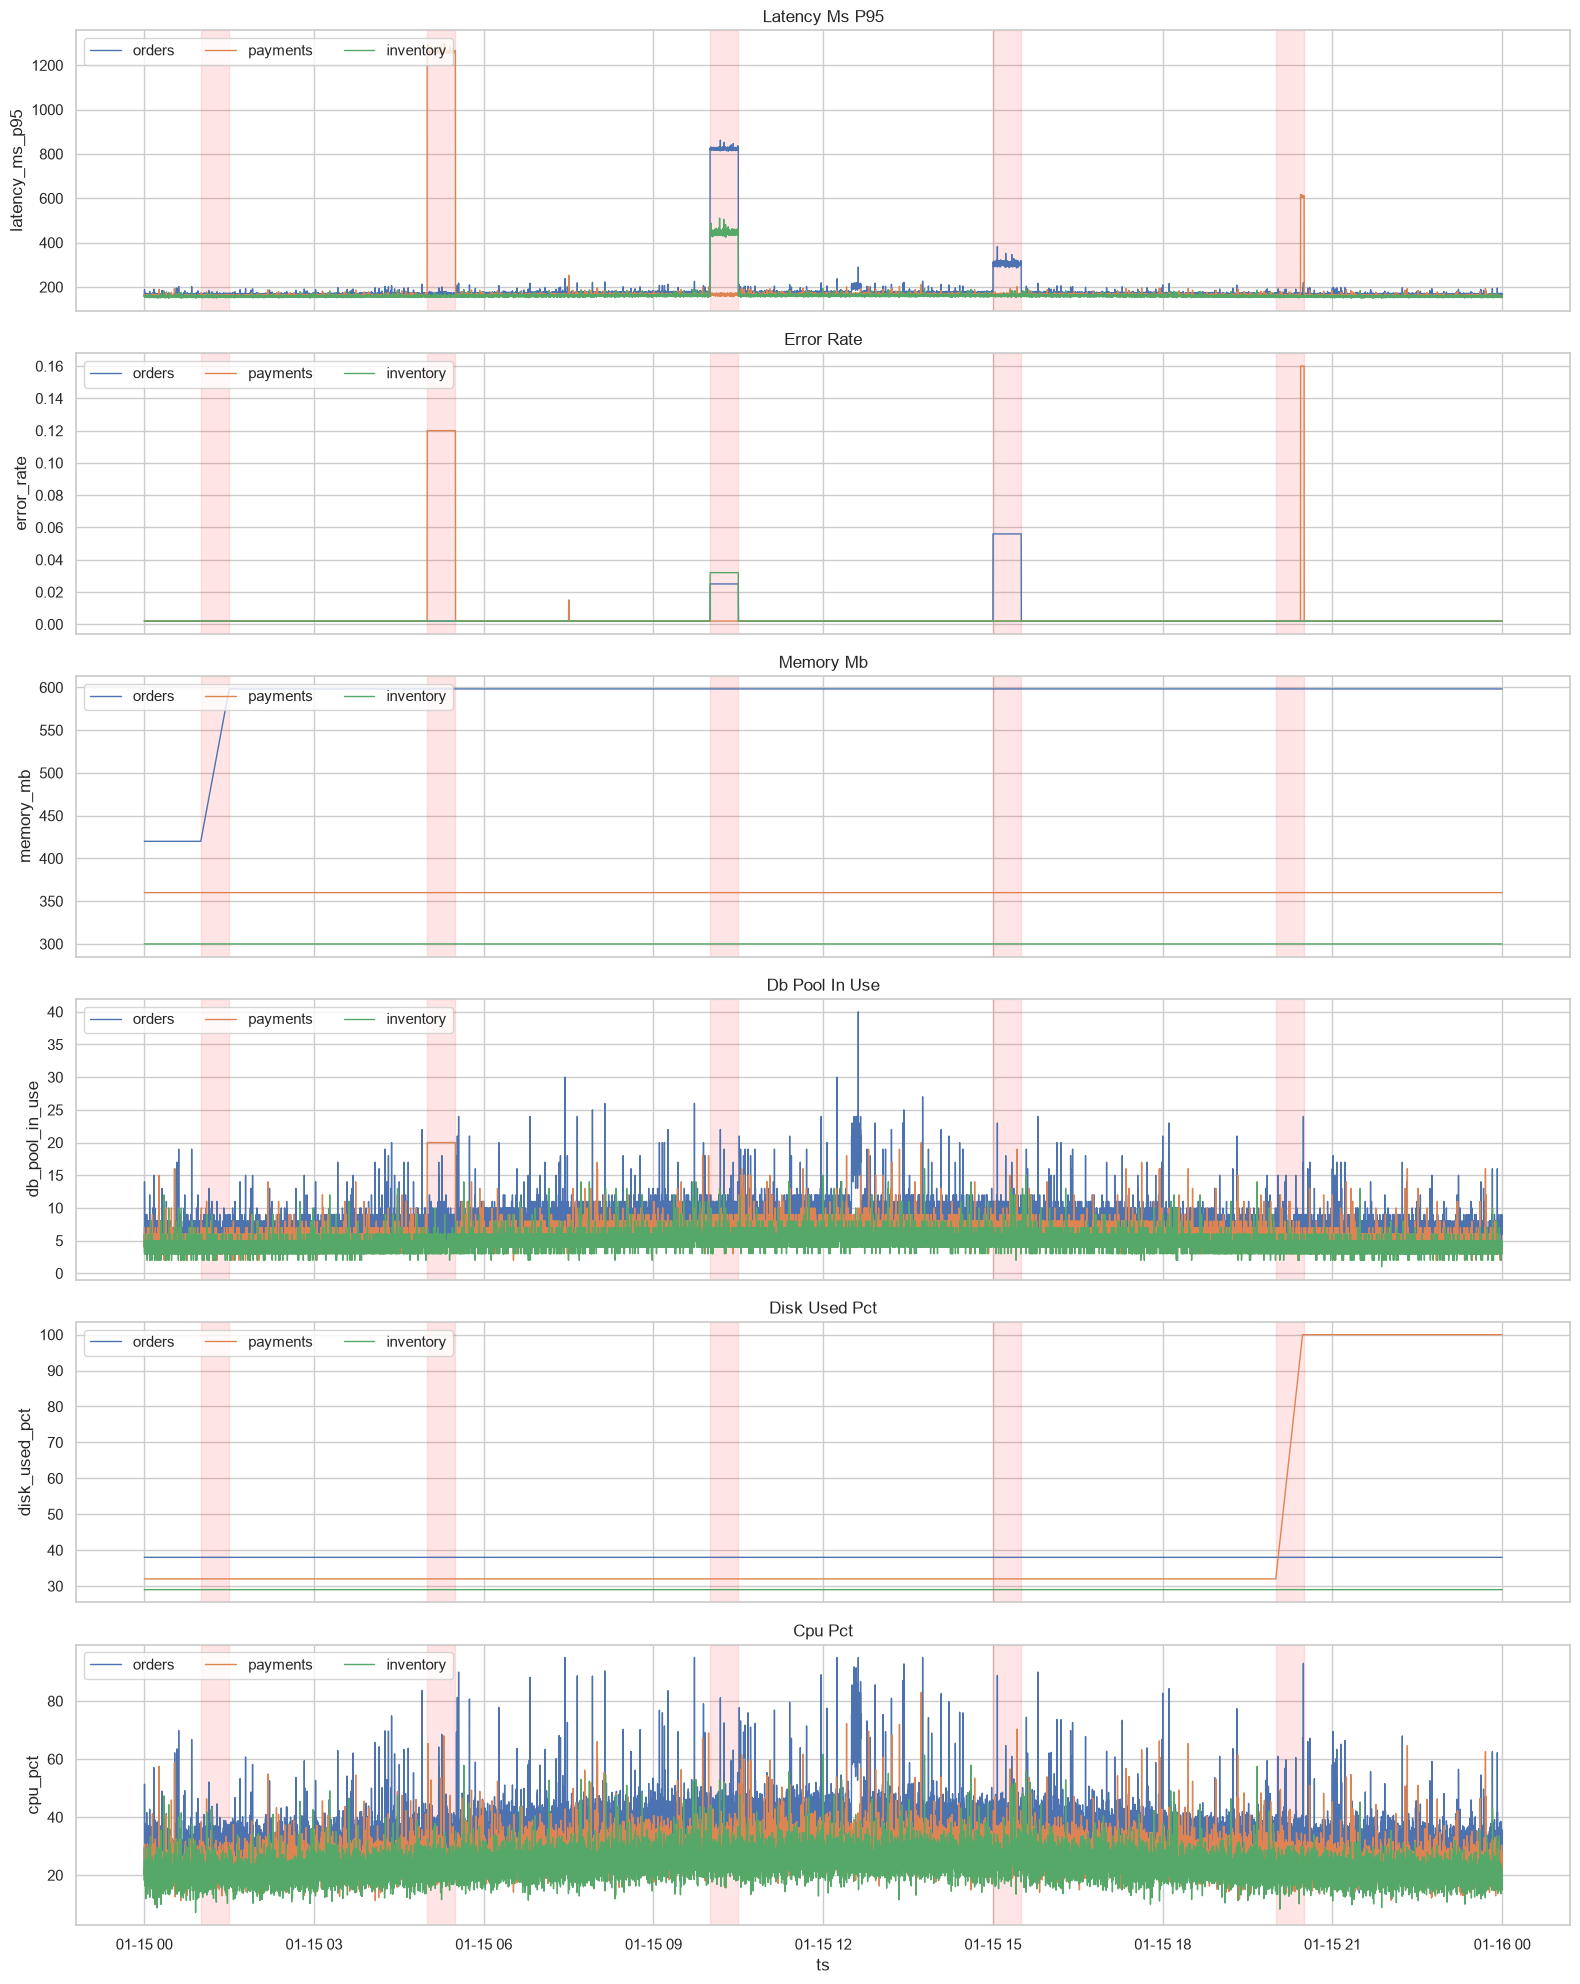

In [5]:
plot_metrics = ["latency_ms_p95", "error_rate", "memory_mb", "db_pool_in_use", "disk_used_pct", "cpu_pct"]
fig, axes = plt.subplots(len(plot_metrics), 1, figsize=(16, 20), sharex=True)
for ax, metric in zip(axes, plot_metrics):
    sns.lineplot(data=metrics, x="ts", y=metric, hue="service", ax=ax, linewidth=1)
    ax.set_title(metric.replace("_", " ").title())
    if not faults.empty:
        for fault in faults.to_dict(orient="records"):
            ax.axvspan(pd.Timestamp(fault["start"]), pd.Timestamp(fault["end"]), alpha=0.10, color="red")
    ax.legend(loc="upper left", ncol=3)
fig.tight_layout()

## Fault signatures versus baseline

For each scheduled fault, compare the affected service during the fault with the 30 minutes before it. This table helps confirm that the simulator creates distinct, explainable signatures.

,,memory_delta_mb,error_delta,p95_delta_ms,pool_utilization,disk_delta_pct,restart_delta
fault_type,service,,,,,,
memory_leak,orders,89.594,0.000,-0.115,0.162,0.000,0.0
db_pool_exhaustion,payments,0.000,0.118,1097.476,0.998,0.000,0.0
slow_dependency,inventory,0.000,0.030,284.281,0.229,0.000,0.0
bad_deployment,orders,0.000,0.054,132.223,0.223,0.000,0.0
disk_full,payments,0.000,0.020,56.611,0.257,36.072,0.0


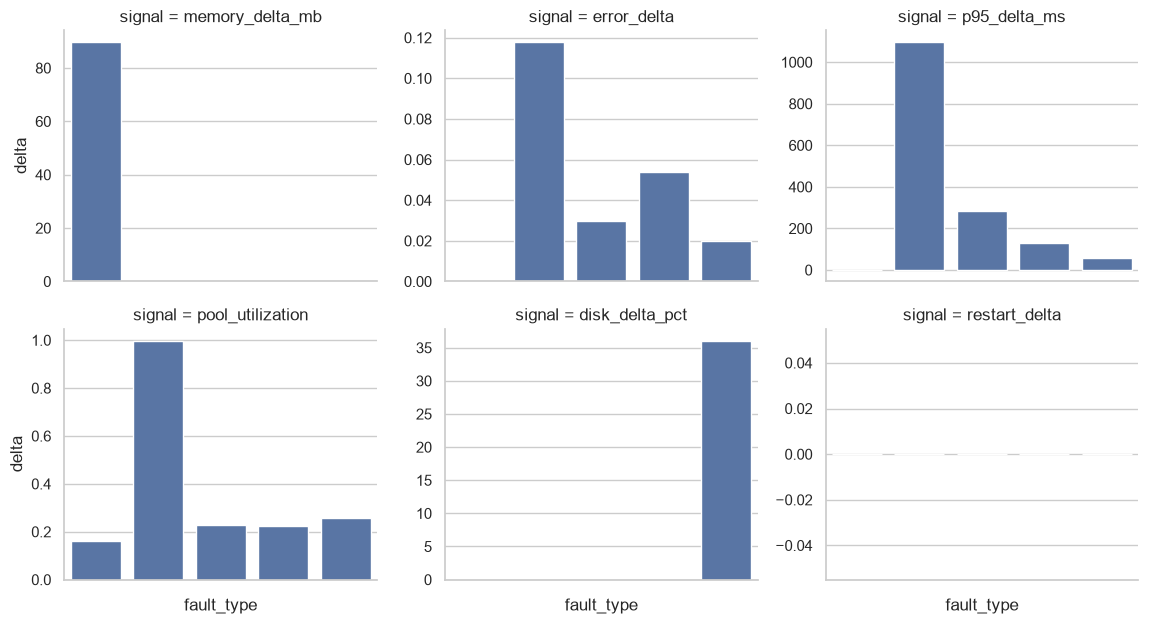

In [6]:
from datetime import timedelta


signature_rows = []
fault_records = faults.to_dict(orient="records") if not faults.empty else []
for fault in fault_records:
    start = pd.Timestamp(fault["start"])
    end = pd.Timestamp(fault["end"])
    service_data = metrics.loc[metrics["service"] == fault["service"]]
    baseline_start = start.to_pydatetime() - timedelta(seconds=1800)
    baseline = service_data.loc[
    (service_data["ts"] >= baseline_start) &
    (service_data["ts"] < start)
    ]
    during = service_data.loc[(service_data["ts"] >= start) & (service_data["ts"] <= end)]
    if baseline.empty or during.empty:
        continue
    before = baseline.mean(numeric_only=True)
    active = during.mean(numeric_only=True)
    signature_rows.append({
        "fault_type": fault["fault_type"],
        "service": fault["service"],
        "memory_delta_mb": active["memory_mb"] - before["memory_mb"],
        "error_delta": active["error_rate"] - before["error_rate"],
        "p95_delta_ms": active["latency_ms_p95"] - before["latency_ms_p95"],
        "pool_utilization": active["db_pool_in_use"] / max(active["db_pool_size"], 1),
        "disk_delta_pct": active["disk_used_pct"] - before["disk_used_pct"],
        "restart_delta": active["restarts_total"] - before["restarts_total"],
    })
signatures = pd.DataFrame(signature_rows)
if not signatures.empty:
    display(signatures.set_index(["fault_type", "service"]).round(3))
    long = signatures.melt(id_vars=["fault_type", "service"], var_name="signal", value_name="delta")
    grid = sns.catplot(data=long, x="fault_type", y="delta", col="signal", col_wrap=3, kind="bar", sharey=False, height=3.2, aspect=1.2)
    grid.set_xticklabels(rotation=45, ha="right")
    grid.fig.tight_layout()
else:
    print("No complete fault interval is present in this run. Increase --hours or check the configured schedule.")